## Initial Exploration

In [929]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
quote_path = "quote.csv.gz"
trade_path = "trade.csv.gz"
quote = pd.read_csv(quote_path)
trade = pd.read_csv(trade_path)

In [930]:
display(quote.head())
display(quote.info())
display(quote.describe())

,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
0,1602206100046531,002202.SZ,11.25,382800,0.00,0
1,1602206100052041,002610.SZ,2.41,154800,0.00,0
2,1602206100053790,002466.SZ,0.00,0,19.00,400
3,1602206100054310,002610.SZ,2.41,154800,2.61,4000
4,1602206100055829,000858.SZ,0.00,0,224.97,5000


<class 'pandas.DataFrame'>
RangeIndex: 1312745 entries, 0 to 1312744
Data columns (total 6 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   recv_time  1312745 non-null  int64  
 1   symbol     1312745 non-null  str    
 2   bid_price  1312745 non-null  float64
 3   bid_size   1312745 non-null  int64  
 4   ask_price  1312745 non-null  float64
 5   ask_size   1312745 non-null  int64  
dtypes: float64(2), int64(3), str(1)
memory usage: 60.1 MB


None

,recv_time,bid_price,bid_size,ask_price,ask_size
count,1.312745e+06,1.312745e+06,1.312745e+06,1.312745e+06,1.312745e+06
mean,1.602215e+15,7.658014e+03,5.158142e+04,7.657961e+03,8.344331e+04
std,6.905859e+09,8.727901e+06,1.854745e+05,8.727901e+06,4.110124e+05
min,1.602206e+15,0.000000e+00,-1.000000e+05,0.000000e+00,-1.000000e+05
25%,1.602209e+15,1.067000e+01,1.300000e+03,1.068000e+01,1.200000e+03
50%,1.602212e+15,1.604000e+01,6.500000e+03,1.603000e+01,5.900000e+03
75%,1.602222e+15,5.642000e+01,2.766700e+04,5.631000e+01,2.800000e+04
max,1.602227e+15,1.000000e+10,3.864600e+06,1.000000e+10,6.773600e+06


note for data cleaning: 
1. turn recev_time to pd.DateTime object
2. bid_size < 0
3. ask_size < 0
4. astronomical ask_price
5. 0 bid_price and ask_price

In [931]:
display(trade.head())
display(trade.info())
display(trade.describe())

,recv_time,symbol,trade_price,trade_qty
0,1602206700206666,000338.SZ,15.64,100
1,1602206700206668,000338.SZ,15.64,2900
2,1602206700206670,000338.SZ,15.64,1500
3,1602206700206672,000338.SZ,15.64,700
4,1602206700206674,000338.SZ,15.64,1500


<class 'pandas.DataFrame'>
RangeIndex: 1158474 entries, 0 to 1158473
Data columns (total 4 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   recv_time    1158474 non-null  int64  
 1   symbol       1158474 non-null  str    
 2   trade_price  1158474 non-null  float64
 3   trade_qty    1158474 non-null  int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 35.4 MB


None

,recv_time,trade_price,trade_qty
count,1.158474e+06,1.158474e+06,1.158474e+06
mean,1.602214e+15,1.285126e+02,8.741242e+04
std,6.929418e+09,9.290882e+04,9.290880e+07
min,1.602207e+15,-1.000000e+05,-1.000000e+05
25%,1.602208e+15,1.074000e+01,1.000000e+02
50%,1.602211e+15,2.059000e+01,3.000000e+02
75%,1.602222e+15,5.669000e+01,8.000000e+02
max,1.602227e+15,1.000000e+08,1.000000e+11


note for data cleaning: 
1. negative trade_price 
2. negative trade_qty
3. astronomical trade_price and trade_qty

## Data Cleaning

clean time and dates

In [932]:
quote["recv_time"] = pd.to_datetime(quote['recv_time'], unit = 'us', utc=True).dt.tz_convert('Asia/Shanghai')
quote = quote.sort_values(['recv_time'], kind='stable').reset_index(drop=True)
trade['recv_time'] = pd.to_datetime(trade['recv_time'], unit='us', utc=True).dt.tz_convert('Asia/Shanghai')
trade = trade.sort_values(['recv_time'],kind='stable').reset_index(drop=True)

In [933]:
display(quote.head())
display(trade.head())

,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
0,2020-10-09 09:15:00.046531+08:00,002202.SZ,11.25,382800,0.00,0
1,2020-10-09 09:15:00.052041+08:00,002610.SZ,2.41,154800,0.00,0
2,2020-10-09 09:15:00.053790+08:00,002466.SZ,0.00,0,19.00,400
3,2020-10-09 09:15:00.054310+08:00,002610.SZ,2.41,154800,2.61,4000
4,2020-10-09 09:15:00.055829+08:00,000858.SZ,0.00,0,224.97,5000


,recv_time,symbol,trade_price,trade_qty
0,2020-10-09 09:25:00.206666+08:00,000338.SZ,15.64,100
1,2020-10-09 09:25:00.206668+08:00,000338.SZ,15.64,2900
2,2020-10-09 09:25:00.206670+08:00,000338.SZ,15.64,1500
3,2020-10-09 09:25:00.206672+08:00,000338.SZ,15.64,700
4,2020-10-09 09:25:00.206674+08:00,000338.SZ,15.64,1500


In [934]:
# how many stocks do we have
print(quote['symbol'].nunique())
print(trade['symbol'].nunique())
set(quote['symbol'].unique()) == set(trade['symbol'].unique())

50
50


True

clean negative numbers

In [935]:
neg_quote = (quote[['bid_price', 'bid_size', 'ask_price', 'ask_size']] < 0).any(axis=1)
quote[neg_quote]

,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
9521,2020-10-09 09:30:06.621334+08:00,000021.SZ,21.18,-100000,21.19,24400
24716,2020-10-09 09:30:38.901682+08:00,000021.SZ,21.11,1900,21.13,-100000


In [936]:
# There are genuine wrong numbers, so drop
quote_clean = quote.loc[~neg_quote].copy()

In [937]:
neg_trade = (trade[['trade_price', 'trade_qty']] < 0).any(axis=1)
trade[neg_trade]

,recv_time,symbol,trade_price,trade_qty
1149612,2020-10-09 15:00:00.453419+08:00,000021.SZ,-100000.00,100
1149614,2020-10-09 15:00:00.453423+08:00,000021.SZ,21.57,-100000


In [938]:
trade_clean = trade.loc[~neg_trade].copy()

inconsistent prices

In [939]:
# usually, ask_price >= bid_price; otherwise, the trade is immediately realized
inconsistent_quote = (quote_clean['ask_price'] < quote_clean['bid_price']) & (quote_clean['ask_price'] > 0)
quote_clean[inconsistent_quote]

,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
1864,2020-10-09 09:30:01.103758+08:00,000021.SZ,1.000000e+10,9900,21.2,10500


In [940]:
quote_clean = quote_clean.loc[~inconsistent_quote].copy()

clean rows where no sells or buys are happening

In [941]:
# two-sided quotes
zero_prices = (quote_clean[['ask_price', 'ask_size', 'bid_price', 'bid_size']] <= 0).any(axis=1)
ts_quote = quote_clean.loc[~zero_prices].copy()

find outliers

trade outliers

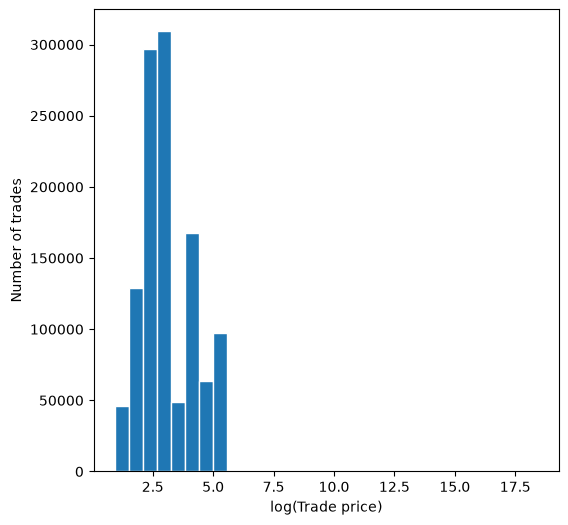

In [942]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.hist(np.log(trade_clean['trade_price']), bins=30, edgecolor='white')
ax.set(xlabel='log(Trade price)', ylabel='Number of trades')
plt.show()

In [943]:
display(trade_clean.nlargest(10, "trade_price"))
display(trade_clean.nlargest(10, "trade_qty"))

,recv_time,symbol,trade_price,trade_qty
4693,2020-10-09 09:25:00.426319+08:00,000021.SZ,99999999.00,100
743484,2020-10-09 13:00:00.888251+08:00,000858.SZ,229.55,300
743485,2020-10-09 13:00:00.888253+08:00,000858.SZ,229.55,100
743486,2020-10-09 13:00:00.888255+08:00,000858.SZ,229.55,100
743487,2020-10-09 13:00:00.888256+08:00,000858.SZ,229.55,400
743488,2020-10-09 13:00:00.888258+08:00,000858.SZ,229.55,600
743489,2020-10-09 13:00:00.888260+08:00,000858.SZ,229.55,300
743513,2020-10-09 13:00:00.899384+08:00,000858.SZ,229.55,971
743483,2020-10-09 13:00:00.888249+08:00,000858.SZ,229.54,100
743426,2020-10-09 13:00:00.841004+08:00,000858.SZ,229.53,300


,recv_time,symbol,trade_price,trade_qty
4701,2020-10-09 09:25:00.426329+08:00,000021.SZ,21.12,99999999999
281558,2020-10-09 09:52:33.241894+08:00,002610.SZ,2.65,872600
469307,2020-10-09 10:21:59.956810+08:00,002466.SZ,21.70,865700
196103,2020-10-09 09:42:55.740258+08:00,002610.SZ,2.60,860800
370849,2020-10-09 10:05:11.701706+08:00,002610.SZ,2.65,855700
666015,2020-10-09 11:05:32.700502+08:00,002610.SZ,2.63,834700
667778,2020-10-09 11:06:01.096264+08:00,002610.SZ,2.63,833800
666616,2020-10-09 11:05:44.952308+08:00,002610.SZ,2.63,818500
372330,2020-10-09 10:05:28.312710+08:00,002610.SZ,2.66,773600
33049,2020-10-09 09:30:30.587919+08:00,002610.SZ,2.58,695000


In [944]:
print(trade_clean['trade_price'].median())
print(trade_clean['trade_qty'].median())

20.59
300.0


In [945]:
trade_clean = trade_clean.loc[trade_clean['trade_price'] < 1000 * trade_clean['trade_price'].median()]
trade_clean = trade_clean.loc[trade_clean['trade_qty'] < 100000 * trade_clean['trade_qty'].median()]


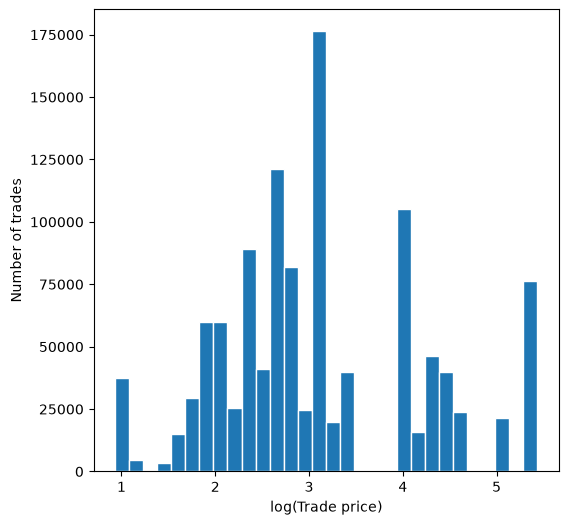

In [946]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.hist(np.log(trade_clean['trade_price']), bins=30, edgecolor='white')
ax.set(xlabel='log(Trade price)', ylabel='Number of trades')
plt.show()

quote outliers

In [947]:
display(ts_quote.nlargest(5, 'ask_price'))
display(ts_quote.nlargest(5, 'ask_size'))
display(ts_quote.nlargest(5, 'bid_price'))
display(ts_quote.nlargest(5, 'bid_size'))

,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
2031,2020-10-09 09:30:01.221329+08:00,000021.SZ,21.19,24500,1.000000e+10,10500
811704,2020-10-09 13:00:00.888260+08:00,000858.SZ,229.55,971,2.295600e+02,1200
811901,2020-10-09 13:00:01.021224+08:00,000858.SZ,229.51,71,2.295500e+02,100
811922,2020-10-09 13:00:01.040975+08:00,000858.SZ,229.51,171,2.295500e+02,100
811925,2020-10-09 13:00:01.043790+08:00,000858.SZ,229.51,71,2.295500e+02,100


,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
1042586,2020-10-09 13:55:06.267191+08:00,002610.SZ,2.64,986595,2.65,6773600
1042607,2020-10-09 13:55:06.673669+08:00,002610.SZ,2.64,986195,2.65,6773600
1042614,2020-10-09 13:55:06.761300+08:00,002610.SZ,2.64,986195,2.65,6772100
1042655,2020-10-09 13:55:07.160719+08:00,002610.SZ,2.64,986195,2.65,6771700
1042703,2020-10-09 13:55:07.974141+08:00,002610.SZ,2.64,986095,2.65,6771700


,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
811704,2020-10-09 13:00:00.888260+08:00,000858.SZ,229.55,971,229.56,1200
810572,2020-10-09 13:00:00.110772+08:00,000858.SZ,229.51,1500,229.52,100
810590,2020-10-09 13:00:00.121038+08:00,000858.SZ,229.51,1400,229.52,100
810593,2020-10-09 13:00:00.132499+08:00,000858.SZ,229.51,1100,229.52,100
810598,2020-10-09 13:00:00.133333+08:00,000858.SZ,229.51,700,229.52,100


,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
1245905,2020-10-09 14:46:00.121090+08:00,002610.SZ,2.61,3657600,2.62,492200
1245660,2020-10-09 14:45:57.139187+08:00,002610.SZ,2.61,3655700,2.62,491900
1245674,2020-10-09 14:45:57.325093+08:00,002610.SZ,2.61,3655700,2.62,480800
1245755,2020-10-09 14:45:58.117116+08:00,002610.SZ,2.61,3651600,2.62,491900
1245787,2020-10-09 14:45:58.351844+08:00,002610.SZ,2.61,3651600,2.62,492200


In [948]:
ts_quote = ts_quote.loc[ts_quote['ask_price'] < 100 * ts_quote['ask_price'].median()].copy()

duplicates

In [949]:
trade_clean.loc[trade_clean.duplicated(keep=False)]

,recv_time,symbol,trade_price,trade_qty
1731,2020-10-09 09:25:00.238087+08:00,000729.SZ,8.11,200
1732,2020-10-09 09:25:00.238087+08:00,000729.SZ,8.11,200
6453,2020-10-09 09:25:00.475186+08:00,000858.SZ,225.00,100
6454,2020-10-09 09:25:00.475186+08:00,000858.SZ,225.00,100
97026,2020-10-09 09:34:15.005136+08:00,000739.SZ,24.23,100
97027,2020-10-09 09:34:15.005136+08:00,000739.SZ,24.23,100
128373,2020-10-09 09:36:41.213948+08:00,000783.SZ,8.12,100
128374,2020-10-09 09:36:41.213948+08:00,000783.SZ,8.12,100
138622,2020-10-09 09:37:32.794803+08:00,002812.SZ,96.48,100
138623,2020-10-09 09:37:32.794803+08:00,002812.SZ,96.48,100


In [950]:
trade_clean = trade_clean.drop_duplicates()
ts_quote = ts_quote.drop_duplicates()

NaN

In [951]:
display(trade_clean.isna().sum())
display(ts_quote.isna().sum())

recv_time      0
symbol         0
trade_price    0
trade_qty      0
dtype: int64

recv_time    0
symbol       0
bid_price    0
bid_size     0
ask_price    0
ask_size     0
dtype: int64

range of time

In [952]:
display(ts_quote['recv_time'].describe())
display(trade_clean['recv_time'].describe())

count                             1311181
mean     2020-10-09 11:40:23.558860+08:00
min      2020-10-09 09:15:00.054310+08:00
25%      2020-10-09 09:56:41.175957+08:00
50%      2020-10-09 10:51:10.353813+08:00
75%      2020-10-09 13:38:49.008021+08:00
max      2020-10-09 15:00:01.110237+08:00
Name: recv_time, dtype: object

count                             1158461
mean     2020-10-09 11:34:54.606887+08:00
min      2020-10-09 09:25:00.206666+08:00
25%      2020-10-09 09:53:41.986112+08:00
50%      2020-10-09 10:43:22.349491+08:00
75%      2020-10-09 13:34:03.466815+08:00
max      2020-10-09 15:00:01.110237+08:00
Name: recv_time, dtype: object

## feature constructions

VWAP in the opening window

first, restrict the time in the window: 09:30–10:00

In [953]:
day = trade_clean['recv_time'].iloc[0].normalize()

q2_start = day + pd.Timedelta('9h30min')
q2_end = day + pd.Timedelta('10h')

q2_trade = trade_clean.loc[
    trade_clean['recv_time'].between(q2_start, q2_end)
].copy()


In [954]:
q2_trade['notional'] = q2_trade['trade_price'] * q2_trade['trade_qty']
by_stock = q2_trade.groupby('symbol')
VWAP = by_stock['notional'].sum() / by_stock['trade_qty'].sum()

largest_stock = VWAP.idxmax()
largest_vwap = VWAP.loc[largest_stock]

print(largest_stock, largest_vwap)

000858.SZ 224.51434205634897


### intraday volume patterns

Compute the total trade volume per stock within each 30-minute window
from 09:30 to 15:00 (CST). For each window, identify the stock with the
highest volume.

In [955]:
q3_start = day + pd.Timedelta('9h30min')
q3_end = day + pd.Timedelta('15h')
q3_trade = trade_clean.loc[trade_clean['recv_time'].between(q3_start, q3_end)].copy()
q3_trade['window'] = q3_trade['recv_time'].dt.floor('30min')
by_window_stock = q3_trade.groupby(['symbol', 'window'])
volume = by_window_stock['trade_qty'].sum()
volume = volume.reset_index(name='volume')

In [956]:
largest_rows = volume.groupby('window')['volume'].idxmax()
leaders = volume.loc[largest_rows]
leaders

,symbol,window,volume
312,002610.SZ,2020-10-09 09:30:00+08:00,101160467
313,002610.SZ,2020-10-09 10:00:00+08:00,49700140
314,002610.SZ,2020-10-09 10:30:00+08:00,20134980
315,002610.SZ,2020-10-09 11:00:00+08:00,20923687
316,002610.SZ,2020-10-09 13:00:00+08:00,12440400
317,002610.SZ,2020-10-09 13:30:00+08:00,7673800
318,002610.SZ,2020-10-09 14:00:00+08:00,10989000
319,002610.SZ,2020-10-09 14:30:00+08:00,14776512


Then describe what you observe across the full day. Are there any
windows that stand out — either very active or very quiet?

Yes, the start of the day is the busiest. There's no trading happening between 12pm to 1pm. and the 13:30 window is the quietest window in the day. Afternoon is generally quieter than the morning.

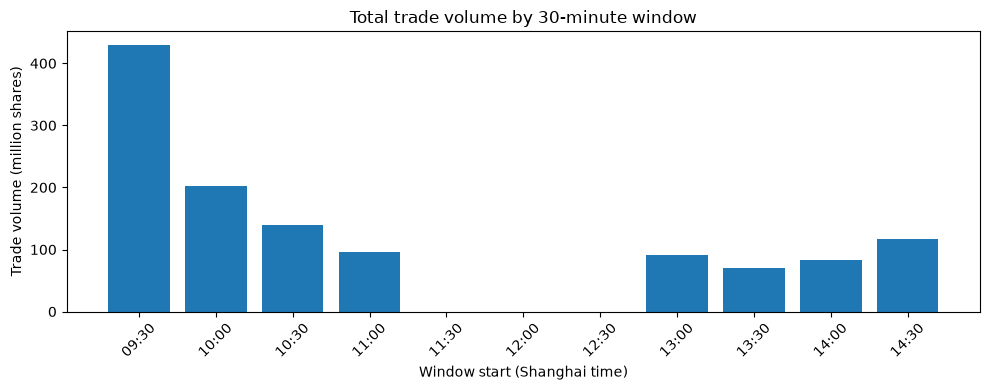

In [957]:
volume_by_window = volume.groupby('window')['volume'].sum()
windows = pd.date_range(q3_start, q3_end, freq='30min', inclusive='left')
volume_by_window = volume_by_window.reindex(windows, fill_value=0)
labels = volume_by_window.index.strftime('%H:%M') # converts each timestamp into a formatted string.

fix, ax = plt.subplots(figsize=(10,4))
ax.bar(labels, volume_by_window/1_000_000)
ax.set(
    title='Total trade volume by 30-minute window',
    xlabel='Window start (Shanghai time)',
    ylabel='Trade volume (million shares)'
)

ax.tick_params(axis='x', rotation=45) # tilt the labels so that they are less likely to overlap

plt.tight_layout()
plt.show()

Liquidity profile and inter-symbol dynamics

Identify the top 5 stocks by total trade volume during the 09:30–15:00
window (CST).

a. Plot the series of per-minute trade volume for each of these 5 stocks.

In [958]:
q4_trade = trade_clean.loc[trade_clean['recv_time'].between(q3_start, q3_end)].copy()
ranked = q4_trade.groupby('symbol')['trade_qty'].sum().sort_values(ascending=False).reset_index(name='volume')
top5 = ranked.head(5)['symbol']
top5

0    002610.SZ
1    002202.SZ
2    000338.SZ
3    000625.SZ
4    002466.SZ
Name: symbol, dtype: str

In [959]:
top5_trades = q4_trade.loc[q4_trade['symbol'].isin(top5)].copy()
top5_trades['minutes'] = top5_trades['recv_time'].dt.floor('1min')
by_minute_vol = top5_trades.groupby(['symbol','minutes'])['trade_qty'].sum()
by_minute_vol = by_minute_vol.reset_index(name='volume')
by_minute_vol

,symbol,minutes,volume
0,000338.SZ,2020-10-09 09:30:00+08:00,4294246
1,000338.SZ,2020-10-09 09:31:00+08:00,1429497
2,000338.SZ,2020-10-09 09:32:00+08:00,1298373
3,000338.SZ,2020-10-09 09:33:00+08:00,920326
4,000338.SZ,2020-10-09 09:34:00+08:00,772457
...,...,...,...
1180,002610.SZ,2020-10-09 14:52:00+08:00,449300
1181,002610.SZ,2020-10-09 14:53:00+08:00,436700
1182,002610.SZ,2020-10-09 14:54:00+08:00,1277900
1183,002610.SZ,2020-10-09 14:55:00+08:00,1210900


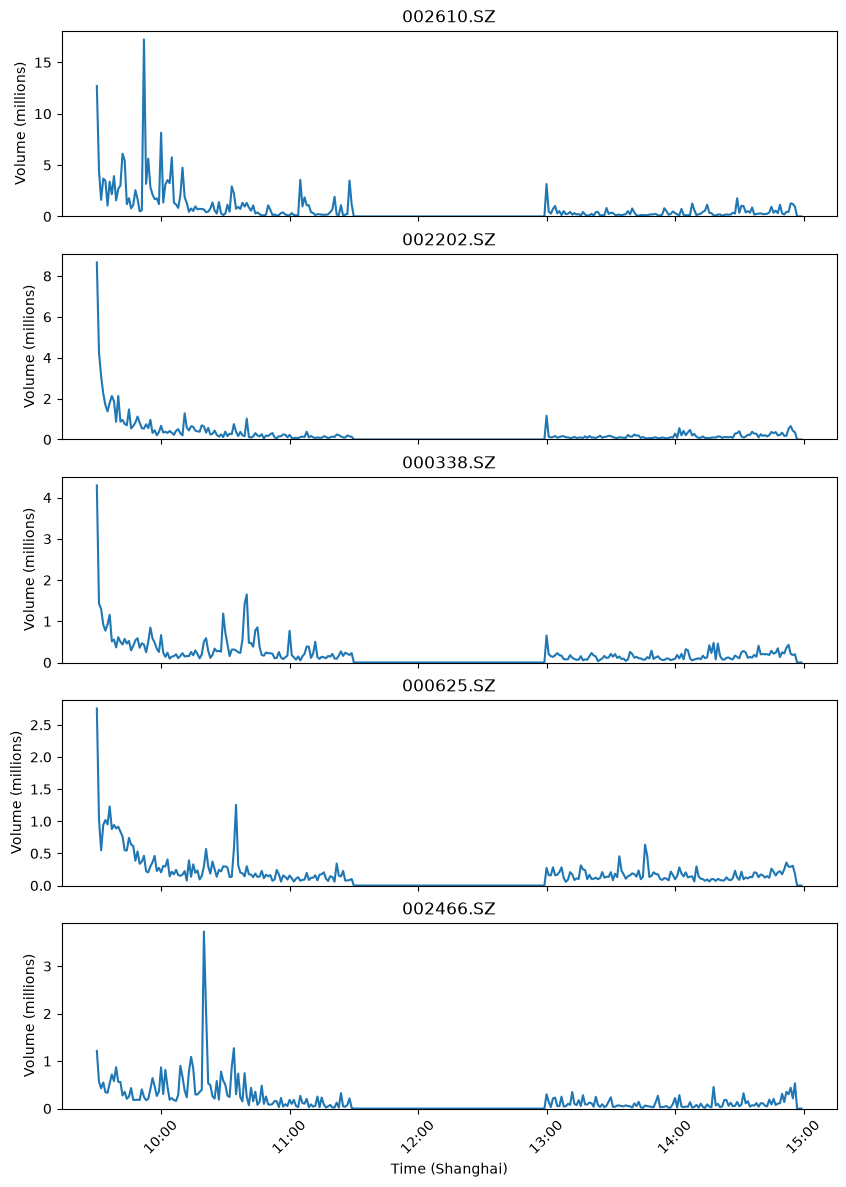

In [960]:
figs, axes = plt.subplots(5,1, figsize= (10,14), sharex=True, sharey=False)
all_minutes = pd.date_range(q3_start, q3_end, freq='min', inclusive='left')

for i, stock in enumerate(top5):
    stock_rows = by_minute_vol.loc[by_minute_vol['symbol'] == stock]
    vol = stock_rows.set_index('minutes')['volume']
    vol = vol.reindex(all_minutes, fill_value=0)

    axes[i].plot(vol.index, vol/1_000_000)
    axes[i].set(
        title=stock,
        ylabel='Volume (millions)'
    )
    axes[i].set_ylim(bottom=0)

# Format the shared time axis in Shanghai time.
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter('%H:%M', tz=all_minutes.tz)
)
axes[-1].set_xlabel('Time (Shanghai)')
axes[-1].tick_params(axis='x', rotation=45)

fig.tight_layout()
plt.show()



b. On the same chart, plot the per-minute average bid-ask spread
derived from quotes.

$$
bid-ask spread = ask_price − bid_price
$$


In [961]:
q4_quote = ts_quote.loc[ts_quote['recv_time'].between(q3_start, q3_end)].copy()
q4_quote = q4_quote.loc[q4_quote['symbol'].isin(top5)]
q4_quote['spread'] = q4_quote['ask_price'] - q4_quote['bid_price']
q4_quote['minutes'] = q4_quote['recv_time'].dt.floor('1min')
by_min_spread = q4_quote.groupby(['symbol', 'minutes'])['spread'].mean()
by_min_spread = by_min_spread.reset_index(name='avg_spread')
by_min_spread 


,symbol,minutes,avg_spread
0,000338.SZ,2020-10-09 09:30:00+08:00,0.018784
1,000338.SZ,2020-10-09 09:31:00+08:00,0.011270
2,000338.SZ,2020-10-09 09:32:00+08:00,0.012590
3,000338.SZ,2020-10-09 09:33:00+08:00,0.012666
4,000338.SZ,2020-10-09 09:34:00+08:00,0.010869
...,...,...,...
1182,002610.SZ,2020-10-09 14:52:00+08:00,0.010000
1183,002610.SZ,2020-10-09 14:53:00+08:00,0.010000
1184,002610.SZ,2020-10-09 14:54:00+08:00,0.010000
1185,002610.SZ,2020-10-09 14:55:00+08:00,0.010000


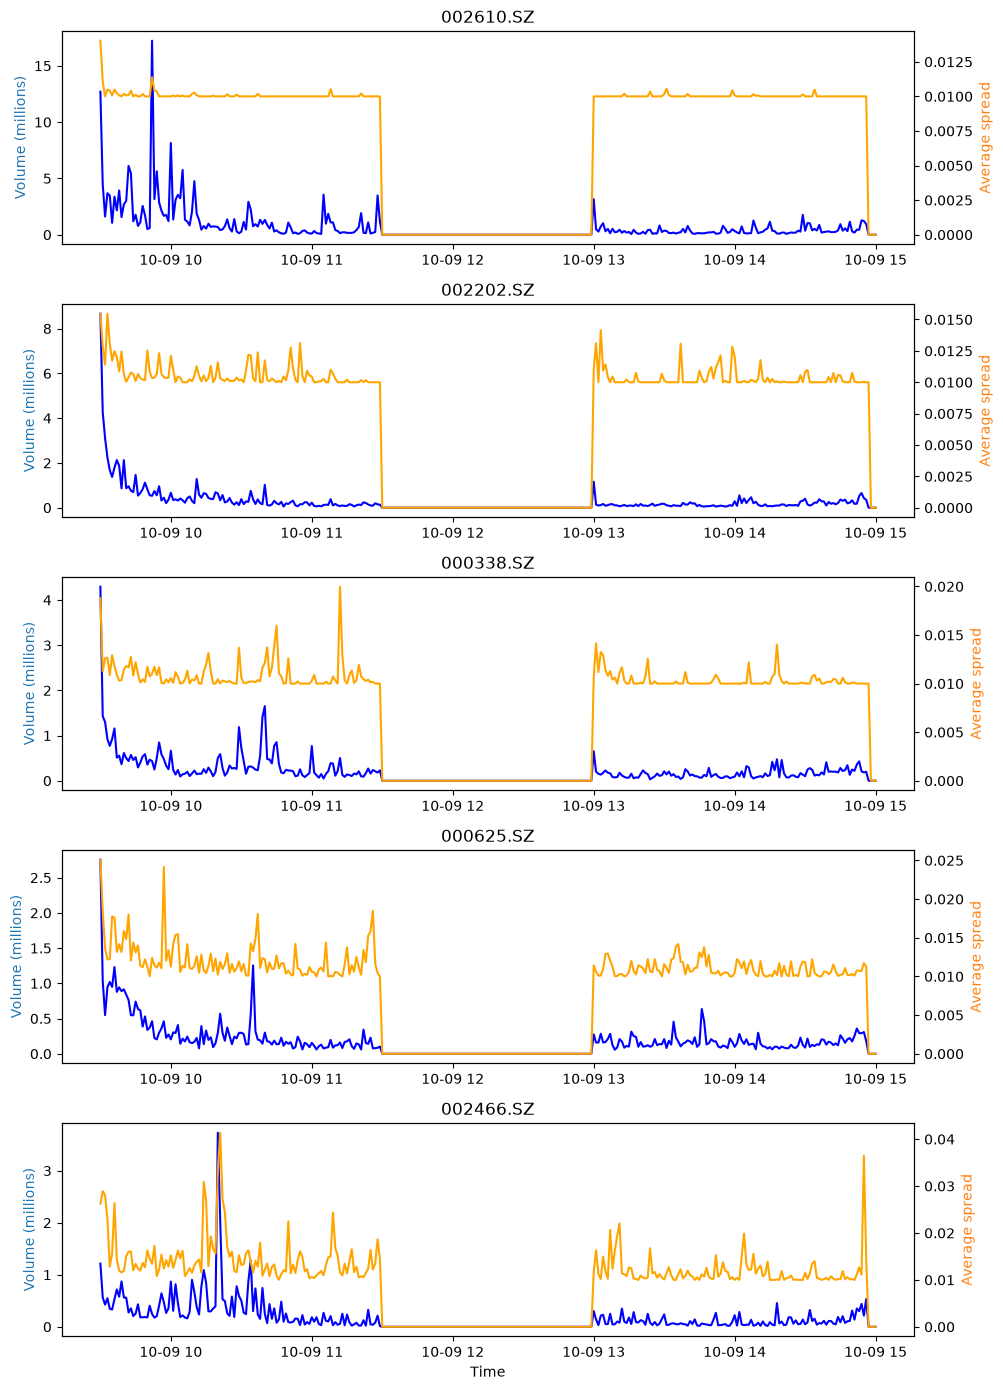

In [962]:
figs, axes = plt.subplots(5,1,figsize=(10,14))
all_minutes = pd.date_range(q3_start, q3_end, freq='min')

for i, stock in enumerate(top5):
    vol_rows = by_minute_vol.loc[by_minute_vol['symbol'] == stock]
    vol = vol_rows.set_index('minutes')['volume']
    vol = vol.reindex(all_minutes, fill_value=0)

    spread_rows = by_min_spread.loc[by_min_spread['symbol'] == stock]
    spread = spread_rows.set_index('minutes')['avg_spread']
    spread = spread.reindex(all_minutes, fill_value=0)

    ax_vol = axes[i]
    ax_spread = ax_vol.twinx()

    ax_vol.plot(spread.index, vol/1_000_000, color='blue')
    ax_spread.plot(spread.index, spread, color='orange')

    ax_vol.set_ylabel('Volume (millions)', color='tab:blue')
    ax_spread.set_ylabel('Average spread', color='tab:orange')
    ax_vol.set_title(stock)


axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()


c. Do the top 5 stocks move together intraday? Compute the pairwise
correlation matrix of their 5-minute volume series. Do you observe any
clustering — stocks whose volume spikes tend to co-occur?

In [963]:
# Assign each minute to a 5-minute bucket
volume_rows = by_minute_vol.copy()
volume_rows['five_minutes'] = volume_rows['minutes'].dt.floor('5min')

# Sum volume within each bucket, with one column per stock
volume_5min = volume_rows.pivot_table(
    index='five_minutes',
    columns='symbol',
    values='volume',
    aggfunc='sum',
    fill_value=0
)
volume_5min = volume_5min.reindex(columns=top5)

# Compute pairwise correlations
corr_matrix = volume_5min.corr()
display(corr_matrix.round(2))

symbol,002610.SZ,002202.SZ,000338.SZ,000625.SZ,002466.SZ
symbol,,,,,
002610.SZ,1.00,0.71,0.64,0.68,0.43
002202.SZ,0.71,1.00,0.90,0.91,0.43
000338.SZ,0.64,0.90,1.00,0.85,0.47
000625.SZ,0.68,0.91,0.85,1.00,0.50
002466.SZ,0.43,0.43,0.47,0.50,1.00


## Spread decomposition for 000021.SZ

Using your cleaned data from Q1, compute for symbol 000021.SZ during
the 09:30–15:00 window (CST):

a. The mean and standard deviation of the bid-ask spread on quotes.

In [964]:
TARGET_STOCK = "000021.SZ"
target_quote = ts_quote.loc[ts_quote['symbol'] == TARGET_STOCK].copy()
target_quote = target_quote.loc[target_quote['recv_time'].between(day,q3_end)]
target_quote['spread'] = target_quote['ask_price'] - target_quote['bid_price']
print(target_quote['spread'].mean())
print(target_quote['spread'].std())
print(target_quote['spread'].median())


0.014463793103448388
0.018218400979166206
0.010000000000001563


b. The median bid-ask spread on trades (Please think carefully how to
align quotes and trades to get bid-ask spread at trade times).
Hint for (b): trades and quotes arrive at different times. You need the most
recent quote available at each trade's timestamp

In [965]:
target_trade = trade_clean.loc[trade_clean['recv_time'].between(q3_start,q3_end)].copy()
target_trade = target_trade.loc[target_trade['symbol'] == TARGET_STOCK]

In [966]:
# Sort both tables by time
target_trade = target_trade.sort_values('recv_time', kind='stable')
target_quote = target_quote.sort_values('recv_time', kind='stable')

# Attach the latest available quote's spread to each trade
target_df = pd.merge_asof(
    target_trade,
    target_quote[['recv_time', 'spread']],
    on='recv_time',
    direction='backward'
)
# direction = 'backward': 
# For each trade, look backward in time 
# and select the most recent quote at or before that trade.

print('Trades with missing spread:', target_df['spread'].isna().sum())
print('Median spread on trades:', target_df['spread'].median())
print('Mean spread on trades:', target_df['spread'].mean())

Trades with missing spread: 0
Median spread on trades: 0.010000000000001563
Mean spread on trades: 0.013426665601533874


c. Compare (a) and (b). If you observe a difference, what does it tell you?

both samples have the same typical spread, but wider spreads receive less weight at trade times, producing a lower trade-time mean.

## Trade flow for 000021.SZ

In [967]:
flow = trade_clean.loc[(
    trade_clean['recv_time'].between(day, q3_end))
    & (trade_clean['symbol'] == TARGET_STOCK)].copy()

flow = flow.sort_values('recv_time', kind='stable')
price_change = flow['trade_price'].diff()
flow['direction'] = np.sign(price_change)
flow['direction'] = flow['direction'].replace(0, np.nan)
flow['direction'] = flow['direction'].ffill()

flow = flow.loc[flow['recv_time'].between(q3_start, q3_end)].copy()


Report the fraction of buyer- vs. seller-initiated trades. 

In [968]:
direction_counts = flow['direction'].value_counts()
fraction = direction_counts / direction_counts.sum()
fraction

direction
 1.0    0.552405
-1.0    0.447595
Name: count, dtype: float64

Then compute the
average bid-ask spread separately on buyer-initiated and seller-initiated
trades. Is there a difference? If so, what might explain it?

In [969]:
q6_quote = ts_quote.loc[
    (ts_quote['recv_time'].between(q3_start, q3_end))
    & (ts_quote['symbol'] == TARGET_STOCK)].copy()
q6_quote['spread'] = q6_quote['ask_price'] - q6_quote['bid_price']
q6_quote = q6_quote.sort_values('recv_time', kind='stable')
flow = pd.merge_asof(flow, q6_quote[['recv_time', 'spread']], on='recv_time', 
                     direction='backward')
flow.head()

,recv_time,symbol,trade_price,trade_qty,direction,spread
0,2020-10-09 09:30:00.065636+08:00,000021.SZ,21.13,400,1.0,NaN
1,2020-10-09 09:30:00.065637+08:00,000021.SZ,21.13,100,1.0,0.01
2,2020-10-09 09:30:00.154885+08:00,000021.SZ,21.14,500,1.0,0.01
3,2020-10-09 09:30:00.190084+08:00,000021.SZ,21.14,800,1.0,0.01
4,2020-10-09 09:30:00.496200+08:00,000021.SZ,21.15,100,1.0,0.01


In [970]:
flow.groupby('direction')['spread'].mean()

direction
-1.0    0.013405
 1.0    0.013444
Name: spread, dtype: float64

Buyer-initiated trades are more frequent and have a slightly higher average quoted spread. However, the difference is only approximately 0.000039, or 0.29% of the seller average, so the spreads are very similar.
The small difference could arise because buyer- and seller-initiated trades occur at different times, when liquidity and volatility differ.

## t-stat of 5-minute open-to-open log-returns

Compute the t-stat of 5-minute open-to-open log-returns for each stock
on quotes. The null hypothesis is that the mean of those log-returns is 0

a. Group the quotes into multiple 5-minute windows

In [971]:
q7_quote = ts_quote.loc[ts_quote['recv_time'].between(q3_start, q3_end)]
q7_quote['5min'] = q7_quote['recv_time'].dt.floor('5min')
q7_quote['midprice'] = (q7_quote['bid_price'] + q7_quote['ask_price'])/2
q7_quote = q7_quote.sort_values('recv_time', kind='stable')

b. Obtain the series of open_mid_price (i.e. the first mid_price you
observe in each window), where
mid_price(t) = 0.5 * (bid_price(t) + ask_price(t)) .

In [972]:
by_stock_window = q7_quote.groupby(['symbol', '5min'])
open_mid_price = by_stock_window['midprice'].first()
open_mid_price = open_mid_price.reset_index(name='open_mid_price')

c. Calculate the t-stat of 5-minute open-to-open log-returns, where
log_return(this_window) = log(open_mid_price(next_window) /
open_mid_price(this_window)) 

You calculate one t-statistic per stock, using that stock’s series of 5-minute log returns.
For one stock, the observations are:
- Return from the 09:30 window’s opening midpoint to the 09:35 window’s opening midpoint.
- Return from 09:35 to 09:40.
- And so on throughout the trading day.
You test whether the mean of these returns is zero:
$$
H_0:\mu_r=0,\qquad
t=\frac{\bar r}{s_r/\sqrt{n}}
$$
Here, $\bar r$ is the average return, $s_r$ is the sample standard deviation of returns, and $n$ is the number of valid returns.

In [973]:
returns = open_mid_price.sort_values(['symbol', '5min']).copy()
by_stock = returns.groupby('symbol')
returns['next_price'] = by_stock['open_mid_price'].shift(-1)
returns['next_window'] = by_stock['5min'].shift(-1)

In [974]:
# Keep only pairs of windows exactly five minutes apart
five_minute_gap = (
    returns['next_window'] - returns['5min'] == pd.Timedelta('5min')
)
returns = returns.loc[five_minute_gap].copy()

# Calculate the natural log of next price / current price
returns['log_return'] = np.log(
    returns['next_price'] / returns['open_mid_price']
)

returns[
    ['symbol', '5min', 'open_mid_price', 'next_price', 'log_return']
].head(10)

,symbol,5min,open_mid_price,next_price,log_return
0,000021.SZ,2020-10-09 09:30:00+08:00,21.145,21.285,0.006599
1,000021.SZ,2020-10-09 09:35:00+08:00,21.285,21.425,0.006556
2,000021.SZ,2020-10-09 09:40:00+08:00,21.425,21.375,-0.002336
3,000021.SZ,2020-10-09 09:45:00+08:00,21.375,21.265,-0.005159
4,000021.SZ,2020-10-09 09:50:00+08:00,21.265,21.325,0.002818
5,000021.SZ,2020-10-09 09:55:00+08:00,21.325,21.440,0.005378
6,000021.SZ,2020-10-09 10:00:00+08:00,21.440,21.655,0.009978
7,000021.SZ,2020-10-09 10:05:00+08:00,21.655,21.615,-0.001849
8,000021.SZ,2020-10-09 10:10:00+08:00,21.615,21.615,0.000000
9,000021.SZ,2020-10-09 10:15:00+08:00,21.615,21.525,-0.004172


In [975]:
by_stock_returns = returns.groupby('symbol')['log_return']

return_stats = by_stock_returns.agg(['count', 'mean', 'std'])

return_stats.head(10)

,count,mean,std
symbol,,,
000021.SZ,46,0.000367,0.003061
000333.SZ,46,0.000034,0.002714
000338.SZ,46,0.000153,0.002430
000402.SZ,46,0.000296,0.002057
000540.SZ,46,0.000064,0.001450
000625.SZ,46,0.000432,0.004419
000703.SZ,46,0.000587,0.003281
000729.SZ,46,0.000332,0.004136
000739.SZ,46,-0.000749,0.004546


In [976]:
return_stats['standard_error'] = (
    return_stats['std'] / np.sqrt(return_stats['count'])
)

return_stats['t_stat'] = (
    return_stats['mean'] / return_stats['standard_error']
)

# The t-statistic is undefined with too few returns or zero variation
invalid = (return_stats['count'] < 2) | (return_stats['std'] == 0)
return_stats.loc[invalid, 't_stat'] = np.nan

return_stats[['count', 'mean', 'std', 'standard_error', 't_stat']]

,count,mean,std,standard_error,t_stat
symbol,,,,,
000021.SZ,46,0.000367,0.003061,0.000451,0.813207
000333.SZ,46,0.000034,0.002714,0.000400,0.085152
000338.SZ,46,0.000153,0.002430,0.000358,0.426055
000402.SZ,46,0.000296,0.002057,0.000303,0.976866
000540.SZ,46,0.000064,0.001450,0.000214,0.299150
000625.SZ,46,0.000432,0.004419,0.000652,0.662749
000703.SZ,46,0.000587,0.003281,0.000484,1.212811
000729.SZ,46,0.000332,0.004136,0.000610,0.543950
000739.SZ,46,-0.000749,0.004546,0.000670,-1.117081


In [977]:
from scipy.stats import t

degrees_of_freedom = return_stats['count'] - 1

# t.sf() gives the right-tail probability of a Student’s t-distribution
return_stats['p_value'] = 2 * t.sf(
    return_stats['t_stat'].abs(),
    df=degrees_of_freedom
)

return_stats[['t_stat', 'p_value']].head()

,t_stat,p_value
symbol,,
000021.SZ,0.813207,0.420381
000333.SZ,0.085152,0.932518
000338.SZ,0.426055,0.672099
000402.SZ,0.976866,0.333858
000540.SZ,0.299150,0.766203


In [978]:
# Include all valid stock-level tests
test_results = return_stats.dropna(subset=['p_value']).copy()
m = len(test_results)

test_results['p_adjusted'] = (
    test_results['p_value'] * m
).clip(upper=1)

test_results['reject_5pct'] = test_results['p_adjusted'] < 0.05

test_results[['t_stat', 'p_value', 'p_adjusted', 'reject_5pct']]

,t_stat,p_value,p_adjusted,reject_5pct
symbol,,,,
000021.SZ,0.813207,0.420381,1.000000,False
000333.SZ,0.085152,0.932518,1.000000,False
000338.SZ,0.426055,0.672099,1.000000,False
000402.SZ,0.976866,0.333858,1.000000,False
000540.SZ,0.299150,0.766203,1.000000,False
000625.SZ,0.662749,0.510872,1.000000,False
000703.SZ,1.212811,0.231531,1.000000,False
000729.SZ,0.543950,0.589161,1.000000,False
000739.SZ,-1.117081,0.269888,1.000000,False


## Predictive model for 10-second log-returns

Train a model that best predicts the 10-second log-returns of mid_price
on quotes and trades. Here mid_price(t) = 0.5 * (bid_price(t) +
ask_price(t)) and 10-second log-return(t) = log(mid_price(t+10
seconds) / mid_price(t)).

Please split the dataset into a 60%–40% partition for training and test
sets. Describe the fitted model (target variable, features, summary
statistics, model choice and hyper-parameters tuning, if any), present
both training and test performance, and compare different approaches if
you try multiple models.

In [979]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

In [980]:
# divide quotes into morning and afternoon sessions
q8_quote = ts_quote[
    ["recv_time", "symbol", "bid_price", "ask_price",
     "bid_size", "ask_size"]
].copy()

q8_quote.sort_values('recv_time', kind='stable')
q8_quote = q8_quote.drop_duplicates(['symbol', 'recv_time'],keep='last')
q8_quote = q8_quote.set_index('recv_time')
q8_quote = pd.concat([
    q8_quote.between_time('9:30', '11:30'),
    q8_quote.between_time('13:00', '15:00')
]).reset_index() # Moves recv_time back into a regular column.

q8_quote['date'] = q8_quote['recv_time'].dt.date
q8_quote['session'] = np.where(q8_quote['recv_time'].dt.hour < 12, 'AM', 'PM')

In [981]:
group_keys = ["symbol", "date", "session"]
q8_quote["mid_price"] = (
    q8_quote["bid_price"] + q8_quote["ask_price"]
) / 2

In [982]:
q8_quote['target_time'] = q8_quote['recv_time'] + pd.Timedelta('10s')

future = q8_quote[
    group_keys + ["recv_time", "mid_price"]
].copy()

# shift time by 10 seconds, so that when merging
# old mid price gets matched to mid price 10s later
future['recv_time'] = (future['recv_time']) - pd.Timedelta(seconds=10)
future = future.rename(columns={'mid_price': 'future_mid'})

# Exclude horizons beyond the last observed quote in each session.
last_time = q8_quote.groupby(group_keys)["recv_time"].transform("max")
current = q8_quote.loc[
    q8_quote["target_time"] <= last_time
].copy()

In [983]:
display(current.columns)
display(future.columns)

Index(['recv_time', 'symbol', 'bid_price', 'ask_price', 'bid_size', 'ask_size',
       'date', 'session', 'mid_price', 'target_time'],
      dtype='str')

Index(['symbol', 'date', 'session', 'recv_time', 'future_mid'], dtype='str')

In [984]:
model_data = pd.merge_asof(
    current.sort_values("recv_time"),
    future.sort_values("recv_time"),
    on="recv_time",
    by=group_keys,
    direction="backward", # Note!
)

model_data["target"] = np.log(
    model_data["future_mid"] / model_data["mid_price"]
)

In [985]:
# 3. Attach the latest trade from the preceding 10 seconds.
q8_trade = trade_clean[
    ["symbol", "recv_time", "trade_price", "trade_qty"]
].copy()
q8_trade = q8_trade.rename(columns={"recv_time": "trade_time"})

model_data = pd.merge_asof(
    model_data.sort_values("recv_time"),
    q8_trade.sort_values("trade_time"),
    left_on="recv_time",
    right_on="trade_time",
    by="symbol",
    direction="backward",
    # Avoid assuming an ordering when timestamps are identical.
    allow_exact_matches=False, # Strictly earlier
    tolerance=pd.Timedelta(seconds=10),
)

# why backwards?
# Q: What trade information was available when Quote B arrived?
# Quote B → earlier Trade

In [986]:
# 4. Construct features available at prediction time.
model_data["relative_spread"] = (
    (model_data["ask_price"] - model_data["bid_price"])
    / model_data["mid_price"]
)

depth = model_data["bid_size"] + model_data["ask_size"]

model_data["imbalance"] = (
    (model_data["bid_size"] - model_data["ask_size"]) / depth
)
model_data["log_depth"] = np.log1p(depth)

model_data["trade_gap"] = (
    model_data["trade_price"] / model_data["mid_price"] - 1
).fillna(0)

model_data["log_trade_qty"] = (
    np.log1p(model_data["trade_qty"]).fillna(0)
)
model_data["has_recent_trade"] = (
    model_data["trade_time"].notna().astype(int)
)

features = [
    "relative_spread",
    "imbalance",
    "log_depth",
    "trade_gap",
    "log_trade_qty",
    "has_recent_trade",
]

assert np.isfinite(model_data[features + ["target"]]).all().all()

In [989]:
# 5. Split chronologically: approximately 60% train, 40% test.
model_data = model_data.sort_values("recv_time").reset_index(drop=True)
test_start = model_data.iloc[int(0.6 * len(model_data))]["recv_time"]

# Remove training labels whose horizons reach the test period.
train = model_data.loc[
    model_data["target_time"] < test_start
].reset_index(drop=True) # give fresh training index from 0

test = model_data.loc[
    model_data["recv_time"] >= test_start
].reset_index(drop=True)

assert train["target_time"].max() < test["recv_time"].min()

In [991]:
X_train = train[features]
y_train = train["target"]
X_test = test[features]
y_test = test["target"]


# 6. Tune using a chronological validation split inside training.
validation_start = train.iloc[int(0.8 * len(train))]["recv_time"]

# These are arrays of row positions telling GridSearchCV 
# which rows to use for fitting and which to use for validation.

# np.flatnonzero() returns the positions where a condition is True
fit_idx = np.flatnonzero(
    train["target_time"] < validation_start
)
validation_idx = np.flatnonzero(
    train["recv_time"] >= validation_start
)

In [ ]:

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])


# Sklearn’s search always chooses the highest score
# so score = - RMSE

search = GridSearchCV(
    estimator=pipeline,
    param_grid={"ridge__alpha": [0.1, 1, 10, 100, 1000]},
    cv=[(fit_idx, validation_idx)],
    scoring="neg_root_mean_squared_error",
    refit=True,
)

# Refit=True fits the selected pipeline on the full training set.
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Validation RMSE (bps):", -search.best_score_ * 10_000)


# 7. Evaluate against a zero-return prediction.
results = []

for name, data in [("Train", train), ("Test", test)]:
    actual = data["target"]
    predicted = search.predict(data[features])

    results.append({
        "set": name,
        "rows": len(data),
        "target_mean_bps": actual.mean() * 10_000,
        "target_std_bps": actual.std() * 10_000,
        "ridge_rmse_bps": (
            np.sqrt(mean_squared_error(actual, predicted)) * 10_000
        ),
        "zero_baseline_rmse_bps": (
            np.sqrt((actual ** 2).mean()) * 10_000
        ),
        "ridge_r2": r2_score(actual, predicted),
    })

print("\nTraining and test performance")
display(pd.DataFrame(results))

print("\nTraining feature and target summary")
display(train[features + ["target"]].describe().T)

Best parameters: {'ridge__alpha': 1000}
Validation RMSE (bps): 8.166625170944227

Training and test performance


,set,rows,target_mean_bps,target_std_bps,ridge_rmse_bps,zero_baseline_rmse_bps,ridge_r2
0,Train,727450,0.258881,13.879670,13.676934,13.882074,0.028999
1,Test,485300,-0.078902,6.824063,6.687139,6.824512,0.039725



Training feature and target summary


,count,mean,std,min,25%,50%,75%,max
relative_spread,727450.0,0.001046,0.001017,0.000044,0.000429,0.000714,0.001356,0.030189
imbalance,727450.0,-0.008627,0.643353,-0.999992,-0.614458,0.000000,0.600000,0.999977
log_depth,727450.0,9.706627,1.871746,4.143135,8.389587,9.705098,10.982454,15.496990
trade_gap,727450.0,0.000014,0.000779,-0.016374,-0.000353,0.000000,0.000357,0.024762
log_trade_qty,727450.0,5.820718,1.423818,0.000000,4.615121,5.707110,6.685861,13.679234
has_recent_trade,727450.0,0.989257,0.103090,0.000000,1.000000,1.000000,1.000000,1.000000
target,727450.0,0.000026,0.001388,-0.027516,-0.000387,0.000000,0.000457,0.016000


In [992]:
# Simple AR(1)-style model:
# Predict the next 10-second return from the previous 10-second return.
# Fit one shared model across stocks, using the existing test_start.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

group_keys = ["symbol", "date", "session"]

ar_data = model_data[
    group_keys + ["recv_time", "target_time", "mid_price", "target"]
].copy()

# Find the midpoint available ten seconds BEFORE each observation.
ar_data["lookback_time"] = (
    ar_data["recv_time"] - pd.Timedelta(seconds=10)
)

past_prices = q8_quote[
    group_keys + ["recv_time", "mid_price"]
].rename(columns={
    "recv_time": "past_quote_time",
    "mid_price": "past_mid",
})

ar_data = pd.merge_asof(
    ar_data.sort_values("lookback_time"),
    past_prices.sort_values("past_quote_time"),
    left_on="lookback_time",
    right_on="past_quote_time",
    by=group_keys,
    direction="backward",
)

ar_data["past_return_10s"] = np.log(
    ar_data["mid_price"] / ar_data["past_mid"]
)

# The first observations in each session lack sufficient history.
ar_data = ar_data.dropna(subset=["past_return_10s", "target"])

# Keep the same chronological split and boundary exclusion.
ar_train = ar_data.loc[ar_data["target_time"] < test_start].copy()
ar_test = ar_data.loc[ar_data["recv_time"] >= test_start].copy()

ar_features = ["past_return_10s"]

ar_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression()),
])

ar_pipeline.fit(ar_train[ar_features], ar_train["target"])

# Evaluate training and test performance.
ar_results = []

for name, data in [("Train", ar_train), ("Test", ar_test)]:
    actual = data["target"]
    predicted = ar_pipeline.predict(data[ar_features])

    ar_results.append({
        "set": name,
        "rows": len(data),
        "ar_rmse_bps": (
            np.sqrt(mean_squared_error(actual, predicted)) * 10_000
        ),
        "zero_baseline_rmse_bps": (
            np.sqrt((actual ** 2).mean()) * 10_000
        ),
        "ar_r2": r2_score(actual, predicted),
    })

display(pd.DataFrame(ar_results))

,set,rows,ar_rmse_bps,zero_baseline_rmse_bps,ar_r2
0,Train,714608,12.818082,12.824783,3.552849e-08
1,Test,479429,6.817025,6.798005,-5.854468e-03
